#  If a martial artist lands 8 distinct roundhouse kick attempts in a match, and each attempt has a 40% chance of scoring a point, what is the probability that they score at least 5 points?

To solve this, I will be using the binomial distribution formula, P(X=k)=(n k)p^k(1−p)^n−k to evaluate the probability of scoring at least 5 points. Considering the information on the question, we know that n = 8 , p = 0.40, and k = 5. Knowing these values and the formula, we can plug in the values into the formula and find the probability. 

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
n = 8
p = 0.40
simulations = 1000

In [3]:
trials = np.random.rand(simulations, n)<p

In [4]:
df = pd.DataFrame(trials, columns=[f"Kick_{i+1}" for i in range(n)])

In [11]:
df["Total Points"] = df.sum(axis=1)

probability = (df["Total Points"] >= 5).mean()

p5 = 56 * (0.40**5) * (0.60**3)
p6 = 28 * (0.40**6) * (0.60**2)
p7 = 8 * (0.40**7) * (0.60**1)
p8 = 1 * (0.40**8) * (0.60**0)
theoreticalProbability = p5 + p6 + p7 + p8

# Displays results
print(f"Theoretical Probability: {theoreticalProbability:.2f}")
print(f"Simulated Probability:   {probability:.2f}")

Theoretical Probability: 0.17
Simulated Probability:   0.88


In [6]:
probabilities = df["Total Points"].value_counts(normalize=True).sort_index() * 100

In [7]:
mean = n * p
std = np.sqrt(n * p * (1 - p))

print(f"Mean: {mean:.2f}")
print(f"Std Dev: {std:.2f}")

Mean: 3.20
Std Dev: 1.39


## Visual: 

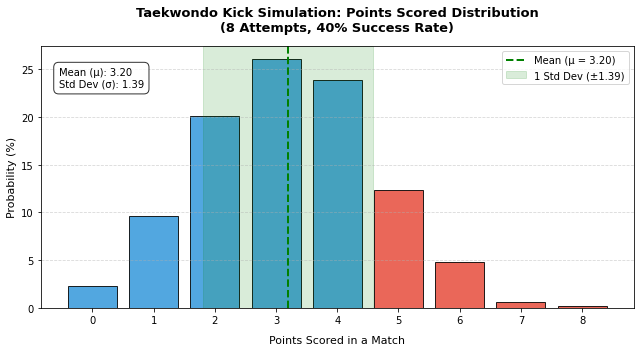

In [8]:
plt.figure(figsize=(9, 5))

colors = ["#e74c3c" if x >= 5 else "#3498db" for x in probabilities.index]

plt.bar(
    probabilities.index,
    probabilities.values,
    color=colors,
    edgecolor="black",
    alpha=0.85,
)

plt.axvline(
    mean,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Mean (μ = {mean:.2f})",
)

plt.axvspan(
    mean - std,
    mean + std,
    color="green",
    alpha=0.15,
    label=f"1 Std Dev (±{std:.2f})",
)

plt.text(
    0.03,
    0.92,
    f"Mean (μ): {mean:.2f}\nStd Dev (σ): {std:.2f}",
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8),
)

plt.title(
    "Taekwondo Kick Simulation: Points Scored Distribution\n(8 Attempts, 40% Success Rate)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)

plt.xlabel("Points Scored in a Match", fontsize=11, labelpad=10)
plt.ylabel("Probability (%)", fontsize=11)
plt.xticks(range(n + 1))
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(loc="upper right")

plt.tight_layout()
plt.show()

# Conclusion:

Based on the simulation, where n=8 and p=0.40, the expected outcome for a martial artial in a match is to score a mean of 3.20 points with a standard deviation of 1.39 points, which makes most of the match's preformances between 1.81 and 4.59 points. The graph implies that the martial artists that score either 3 or 4 happened to be the most common outcome which has a likelihood of 51.2% when combined. The theoretical probability of achieving a target of at least 5 points only occurs in about 17.37% of the simulated matches. This shows that scoring 5 or more points can be attained but it represents an above-average preformance during a match.